# Prática 6 - Regressão logística e SHAP
**Valentim Soares de Andrade Neto | 2019027210**

Objetivo: classificar tumores do Breast Cancer Wisconsin (Diagnostic), avaliar o modelo em teste e explicar suas previsões. Rótulos originais: **0 = maligno, 1 = benigno**. Não há ajuste de hiperparâmetros usando o teste.


In [1]:
from pathlib import Path
import json, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, shap
from scipy.special import expit
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, classification_report, RocCurveDisplay
from IPython.display import display
OUT = Path('output'); FIG = OUT / 'figuras'; FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid')
def salvar(nome):
    plt.savefig(FIG / (nome + '.png'), dpi=170, bbox_inches='tight')
    plt.show(); plt.close()
dados = load_breast_cancer()
X = pd.DataFrame(dados.data, columns=dados.feature_names)
y = pd.Series(dados.target, index=X.index, name='diagnosis')
display(X.head())
print(X.shape, 'Ausentes:', X.isna().sum().sum(), 'Duplicados:', X.duplicated().sum())
display(y.value_counts().rename(index={0: 'Maligno', 1: 'Benigno'}))
display(X.describe().T)
X.describe().T.to_csv(OUT / 'resumo_estatistico.csv')


/tmp/pt06-env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


(569, 30) Ausentes: 0 Duplicados: 0


diagnosis
Benigno    357
Maligno    212
Name: count, dtype: int64

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


## 1. Exploração
São 569 amostras, 30 atributos numéricos e duas classes. Os atributos são derivados de imagens de punção aspirativa por agulha fina: raio, textura, perímetro, área, suavidade, compacidade, concavidade, pontos côncavos, simetria e dimensão fractal, com média, erro padrão e “worst” (média dos três maiores valores). Não há necessidade de imputação. Os gráficos exploratórios usam o conjunto completo apenas para descrição; o pré-processamento e o modelo usam somente o treino.


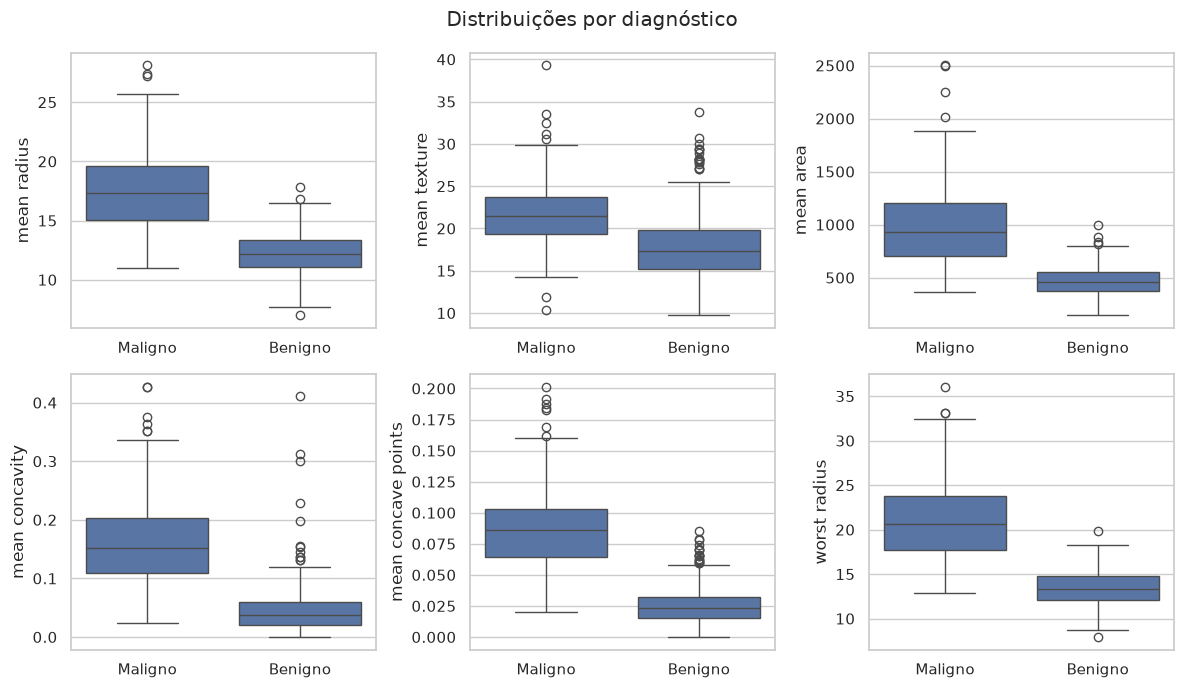

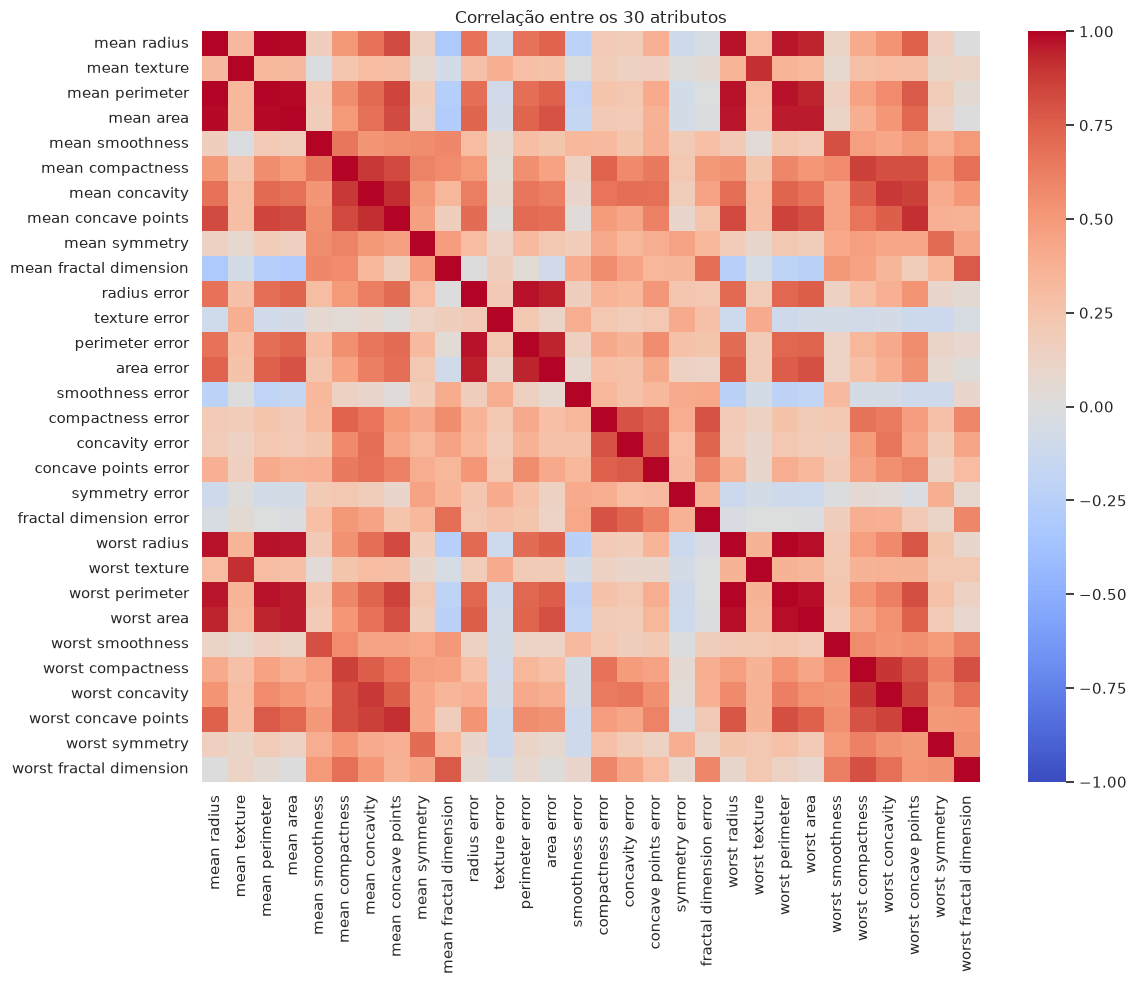

In [2]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
features = ['mean radius', 'mean texture', 'mean area', 'mean concavity', 'mean concave points', 'worst radius']
for ax, feature in zip(axes.flat, features):
    sns.boxplot(x=y.map({0:'Maligno', 1:'Benigno'}), y=X[feature], ax=ax)
    ax.set(xlabel='', ylabel=feature)
fig.suptitle('Distribuições por diagnóstico'); plt.tight_layout(); salvar('distribuicoes')
plt.figure(figsize=(12, 10))
sns.heatmap(X.corr(), cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.title('Correlação entre os 30 atributos'); plt.tight_layout(); salvar('correlacoes')


Raio, perímetro e área representam aspectos relacionados ao tamanho e são fortemente correlacionados. As classes mostram diferenças nas distribuições, com sobreposição. Essa redundância deve ser considerada ao interpretar a importância individual dos atributos.

## 2. Divisão, padronização e treinamento
Reproduzimos a divisão do exemplo: 80%/20%, `random_state=42`, sem estratificação. O StandardScaler aprende média e desvio padrão somente nos 455 registros de treino; o teste contém 114 registros. A regressão logística usa regularização L2, C=1, solver lbfgs e máximo de 2.000 iterações. P(maligno) corresponde à coluna da classe 0.


Acurácia: 0.9736842105263158 AUC (maligno positivo): 0.99737962659679
              precision    recall  f1-score   support

     Maligno       0.98      0.95      0.96        43
     Benigno       0.97      0.99      0.98        71

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



col_0,Teste,Treino
diagnosis,,
0,43,169
1,71,286


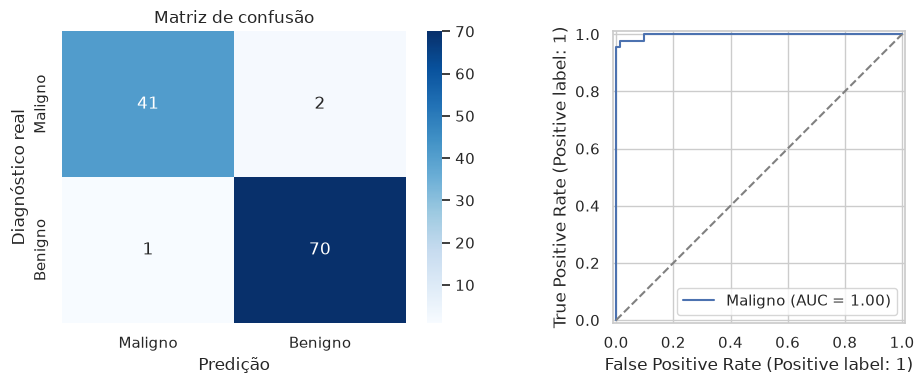

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=42)
scaler = StandardScaler()
Z_train = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
Z_test = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)
modelo = LogisticRegression(C=1, solver='lbfgs', max_iter=2000, random_state=42)
modelo.fit(Z_train, y_train)
pred = modelo.predict(Z_test)
prob_maligno = modelo.predict_proba(Z_test)[:, list(modelo.classes_).index(0)]
acc = accuracy_score(y_test, pred)
auc = roc_auc_score((y_test == 0).astype(int), prob_maligno)
cm = confusion_matrix(y_test, pred, labels=[0, 1])
print('Acurácia:', acc, 'AUC (maligno positivo):', auc)
print(classification_report(y_test, pred, target_names=['Maligno', 'Benigno']))
display(pd.crosstab(y, pd.Series(np.where(X.index.isin(X_train.index), 'Treino', 'Teste'), index=X.index)))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Maligno','Benigno'], yticklabels=['Maligno','Benigno'], ax=axes[0])
axes[0].set(xlabel='Predição', ylabel='Diagnóstico real', title='Matriz de confusão')
RocCurveDisplay.from_predictions((y_test == 0).astype(int), prob_maligno, ax=axes[1], name='Maligno')
axes[1].plot([0,1],[0,1], '--', color='gray'); plt.tight_layout(); salvar('avaliacao')


## 3. Explicações SHAP globais
O LinearExplainer com masker Independent usa todos os registros padronizados de treino como referência. Explica f(x) = log(P(benigno)/P(maligno)), e não a probabilidade diretamente. SHAP positivo favorece benigno; negativo favorece maligno. A probabilidade benigna é sigmoid(f(x)); a maligna é 1 - sigmoid(f(x)). O valor base é a média dos **log-odds** no treino, diferente do logit da probabilidade média.

Sob essa referência independente, φ_j = coef_j × (z_j - média_treino_j). Verificamos a soma aditiva para todas as amostras de teste e a equivalência com as probabilidades. As correlações não são repartidas entre os atributos: o ranking descreve este modelo e esta referência, sem demonstrar causalidade.


,variavel,media_abs_shap,coeficiente
21,worst texture,1.129370,-1.350606
7,mean concave points,0.964159,-1.119804
10,radius error,0.874583,-1.268178
28,worst symmetry,0.823161,-1.208200
26,worst concavity,0.715418,-0.943053
20,worst radius,0.712240,-0.879840
27,worst concave points,0.666807,-0.778217
23,worst area,0.651629,-0.841846
6,mean concavity,0.629232,-0.801458
13,area error,0.525310,-0.907186


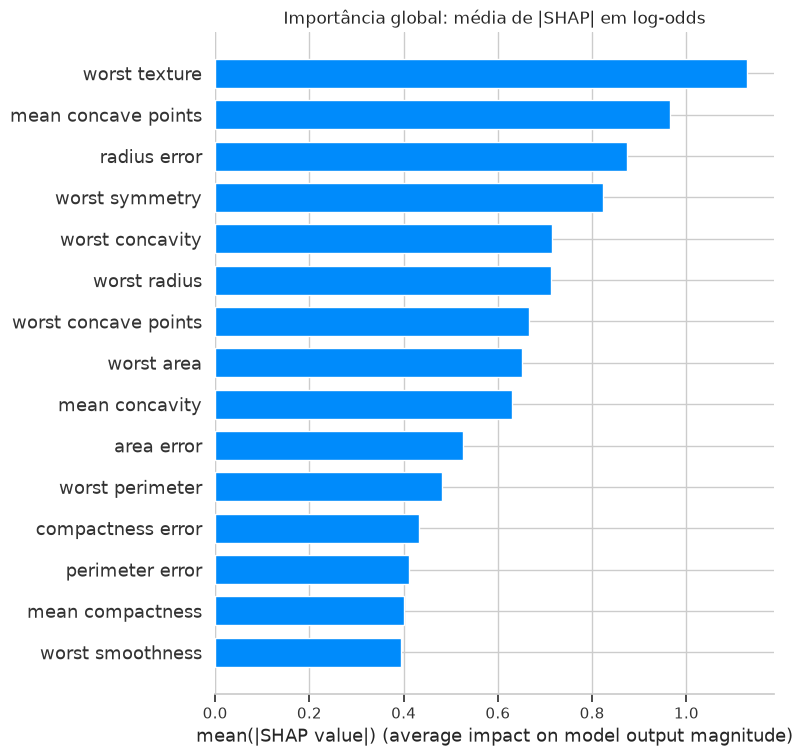

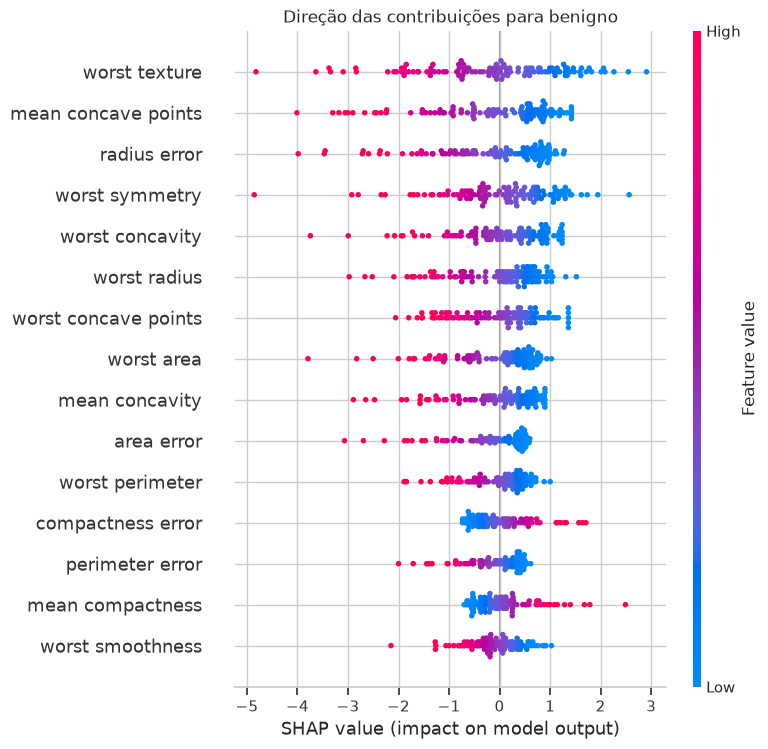

In [4]:
masker = shap.maskers.Independent(Z_train, max_samples=len(Z_train))
explainer = shap.LinearExplainer(modelo, masker)
sv = explainer(Z_test)
scores = modelo.decision_function(Z_test)
erro = float(np.max(np.abs(sv.base_values + sv.values.sum(axis=1) - scores)))
assert np.allclose(sv.base_values + sv.values.sum(axis=1), scores)
assert np.allclose(1-expit(scores), prob_maligno)
assert np.allclose(sv.values, (Z_test.to_numpy()-Z_train.mean().to_numpy())*modelo.coef_[0])
ranking = pd.DataFrame({'variavel': X.columns, 'media_abs_shap': np.abs(sv.values).mean(axis=0), 'coeficiente': modelo.coef_[0]}).sort_values('media_abs_shap', ascending=False)
display(ranking.head(10)); ranking.to_csv(OUT / 'importancia_shap.csv', index=False)
shap.summary_plot(sv.values, Z_test, plot_type='bar', max_display=15, show=False)
plt.title('Importância global: média de |SHAP| em log-odds'); salvar('shap_bar')
shap.summary_plot(sv.values, Z_test, max_display=15, show=False)
plt.title('Direção das contribuições para benigno'); salvar('shap_beeswarm')


## 4. Três pacientes do teste
São usados os três primeiros registros na ordem devolvida pela divisão, sem seleção baseada no resultado. As barras vermelhas aumentam os log-odds de benignidade; as azuis os reduzem. Os valores apresentados junto aos atributos estão padronizados. A tabela exportada conserva os valores originais.


Paciente 1, índice 204: real=Benigno, predito=Benigno, P(maligno)=11.3590%, f(x)=2.0546


,variavel,valor_original,shap
0,mean concave points,0.03821,0.296601
1,worst area,677.90000,0.295567
2,worst smoothness,0.14260,-0.261212
3,compactness error,0.01911,-0.239615


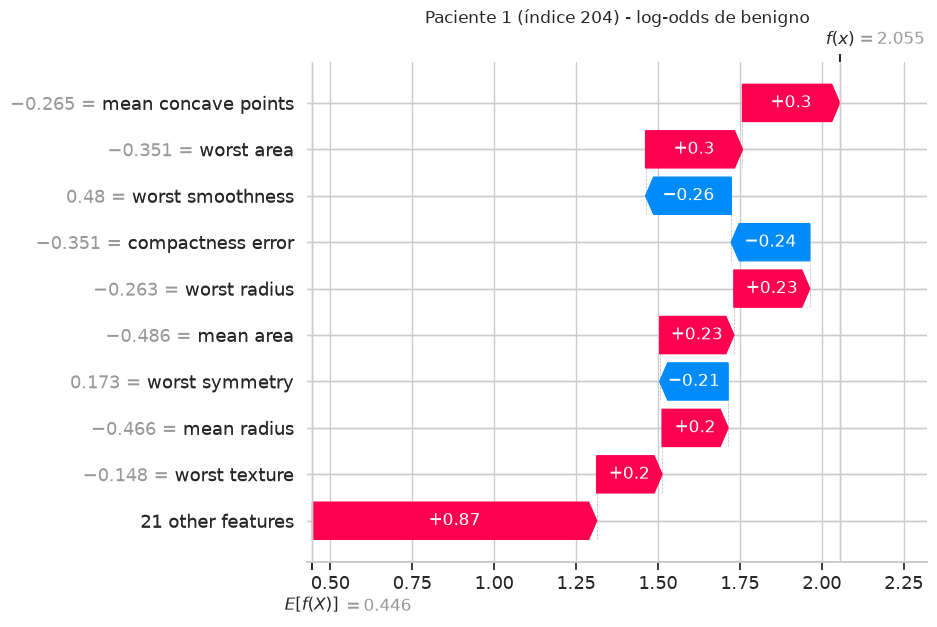

Principais contribuições: mean concave points: +0.297, favorece benigno; worst area: +0.296, favorece benigno; worst smoothness: -0.261, favorece maligno; compactness error: -0.240, favorece maligno
Paciente 2, índice 70: real=Maligno, predito=Maligno, P(maligno)=99.9991%, f(x)=-11.6172


,variavel,valor_original,shap
0,radius error,0.7888,-1.734177
1,worst radius,24.8600,-1.578978
2,worst area,1866.0000,-1.468298
3,area error,96.0500,-1.076269


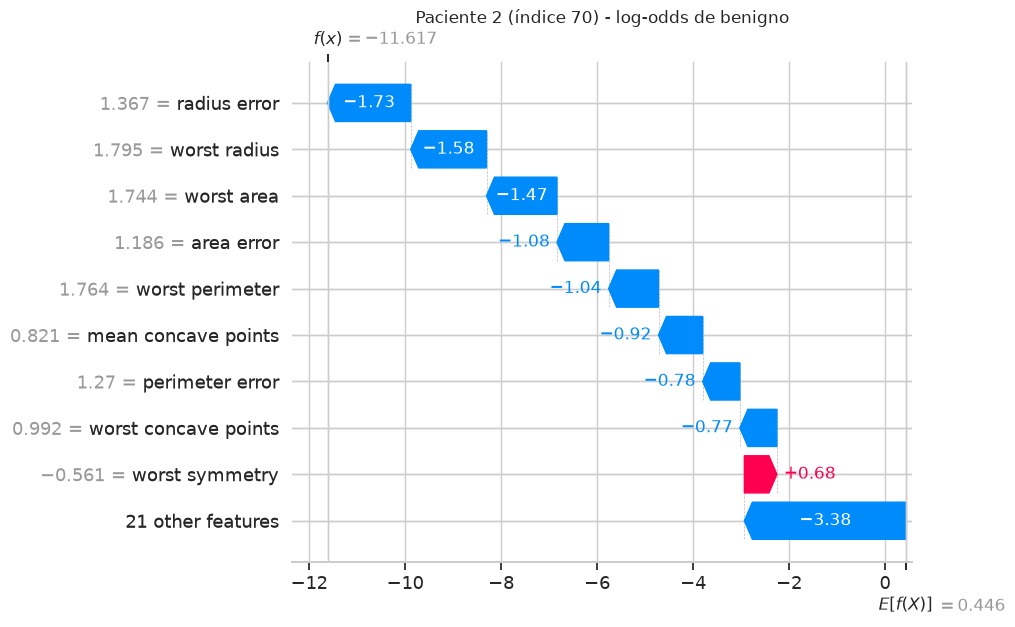

Principais contribuições: radius error: -1.734, favorece maligno; worst radius: -1.579, favorece maligno; worst area: -1.468, favorece maligno; area error: -1.076, favorece maligno
Paciente 3, índice 131: real=Maligno, predito=Maligno, P(maligno)=99.6921%, f(x)=-5.7800


,variavel,valor_original,shap
0,mean concave points,0.08087,-0.959920
1,mean concavity,0.14660,-0.582582
2,worst radius,19.26000,-0.553774
3,worst smoothness,0.15460,-0.544423


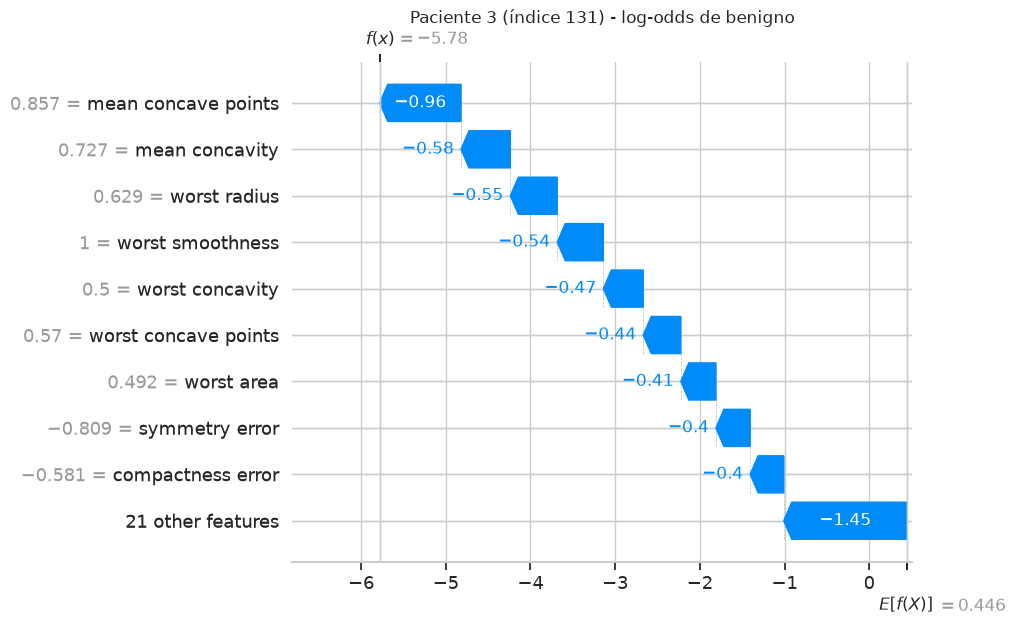

Principais contribuições: mean concave points: -0.960, favorece maligno; mean concavity: -0.583, favorece maligno; worst radius: -0.554, favorece maligno; worst smoothness: -0.544, favorece maligno


4200

In [5]:
pacientes = []
for i in range(3):
    idx = int(X_test.index[i]); order = np.argsort(-np.abs(sv.values[i]))[:4]
    registro = {'indice': idx, 'real': 'Maligno' if y_test.iloc[i]==0 else 'Benigno', 'predito': 'Maligno' if pred[i]==0 else 'Benigno', 'p_maligno': float(prob_maligno[i]), 'base': float(sv.base_values[i]), 'score': float(scores[i]), 'principais': [{'variavel': str(X.columns[j]), 'valor_original':float(X_test.iloc[i,j]), 'shap':float(sv.values[i,j])} for j in order]}
    pacientes.append(registro)
    print(f"Paciente {i+1}, índice {idx}: real={registro['real']}, predito={registro['predito']}, P(maligno)={prob_maligno[i]:.4%}, f(x)={scores[i]:.4f}")
    display(pd.DataFrame(registro['principais']))
    shap.plots.waterfall(sv[i], max_display=10, show=False)
    plt.title(f'Paciente {i+1} (índice {idx}) - log-odds de benigno'); salvar(f'paciente_{i+1}')
    print('Principais contribuições:', '; '.join(f"{r['variavel']}: {r['shap']:+.3f}, favorece " + ('benigno' if r['shap']>0 else 'maligno') for r in registro['principais']))
pd.DataFrame(sv.values, index=X_test.index, columns=X.columns).to_csv(OUT / 'shap_teste.csv', index_label='indice')
X_test.to_csv(OUT / 'atributos_teste.csv', index_label='indice')
pd.DataFrame({'real':y_test, 'predito':pred, 'p_maligno':prob_maligno}).to_csv(OUT / 'predicoes.csv', index_label='indice')
resultados = {'acuracia':float(acc), 'auc_maligno':float(auc), 'matriz_confusao':cm.tolist(), 'sensibilidade_maligno':float(cm[0,0]/cm[0].sum()), 'especificidade':float(cm[1,1]/cm[1].sum()), 'treino':len(X_train), 'teste':len(X_test), 'classes':{str(k):int(v) for k,v in y.value_counts().items()}, 'base':float(sv.base_values[0]), 'erro_aditividade':erro, 'ranking':ranking.head(10).to_dict('records'), 'pacientes':pacientes, 'versoes':{'python':platform.python_version(), 'numpy':np.__version__, 'pandas':pd.__version__, 'sklearn':sklearn.__version__, 'shap':shap.__version__}}
(OUT / 'resultados.json').write_text(json.dumps(resultados, ensure_ascii=False, indent=2), encoding='utf-8')


## 5. Discussão e referências
O ranking calculado acima permite identificar os atributos de maior impacto médio no teste. As explicações locais mostram por que a mesma variável pode contribuir de modos diferentes conforme o valor observado. Características de tamanho e irregularidade têm plausibilidade na discriminação de tumores; o sinal deve ser lido junto ao coeficiente e ao valor padronizado, considerando a redundância entre medições. SHAP não estabelece efeito causal nem garante generalização fora desta amostra.

A acurácia e AUC avaliam aspectos distintos: decisões no limiar 0,5 e ordenação dos riscos em vários limiares. Os erros da matriz de confusão permanecem relevantes mesmo com AUC elevada. O estudo utiliza uma única divisão, não avalia calibração nem validação externa e tem finalidade didática.

- [Dataset e atributos - scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html)
- [LinearExplainer - SHAP](https://shap.readthedocs.io/en/latest/generated/shap.LinearExplainer.html)
- [Waterfall - SHAP](https://shap.readthedocs.io/en/latest/generated/shap.plots.waterfall.html)
